In [10]:
!pip install yfinance pandas numpy matplotlib pandas_datareader seaborn

  Using cached yfinance-1.8.0-py3-none-any.whl.metadata (6.8 kB)
  Using cached pandas_datareader-0.11.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached curl_cffi-0.17.0-cp310-abi3-win_amd64.whl.metadata (19 kB)
  Using cached peewee-4.5.3-py3-none-any.whl.metadata (10 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
Using cached yfinance-1.8.0-py3-none-any.whl (158 kB)
Using cached pandas_datareader-0.11.1-py3-none-any.whl (65 kB)
Using cached curl_cffi-0.17.0-cp310-abi3-win_amd64.whl (2.1 MB)
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------- ----------------------------- 1.0/4.0 MB 8.4 MB/s eta 0:00:01
   ------------------------------- -------- 3.1/4.0 MB 9.8 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 8.9 MB/s  0:00:00
Using cached peewee-4.5.3-py3-none-any.

## Define the dates and tickers
For now, let's use 2015–2025 as an initial research period.

In [11]:
%pip uninstall -y pandas numpy yfinance

Found existing installation: pandas 3.1.1
Uninstalling pandas-3.1.1:
  Successfully uninstalled pandas-3.1.1
Found existing installation: numpy 2.5.4
Uninstalling numpy-2.5.4:
  Successfully uninstalled numpy-2.5.4
Found existing installation: yfinance 1.8.0
Uninstalling yfinance-1.8.0:
  Successfully uninstalled yfinance-1.8.0
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.
You can safely remove it manually.
You can safely remove it manually.


In [12]:
%pip install --no-cache-dir --upgrade numpy pandas yfinance matplotlib seaborn

   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/12.6 MB 11.1 MB/s eta 0:00:02
   ----------- ---------------------------- 3.7/12.6 MB 10.6 MB/s eta 0:00:01
   -------------------- ------------------- 6.3/12.6 MB 11.1 MB/s eta 0:00:01
   --------------------------- ------------ 8.7/12.6 MB 11.3 MB/s eta 0:00:01
   -------------------------------- ------- 10.2/12.6 MB 10.8 MB/s eta 0:00:01
   ---------------------------------------- 12.6/12.6 MB 10.6 MB/s  0:00:01
   ---------------------------------------- 0.0/10.7 MB ? eta -:--:--
   ---- ----------------------------------- 1.3/10.7 MB 7.0 MB/s eta 0:00:02
   ------- -------------------------------- 2.1/10.7 MB 5.7 MB/s eta 0:00:02
   ------------ --------------------------- 3.4/10.7 MB 5.8 MB/s eta 0:00:02
   ------------------- -------------------- 5.2/10.7 MB 6.2 MB/s eta 0:00:01
   ----------------------- ---------------- 6.3/10.7 MB 6.4 MB/s eta 0:00:01
   -----

In [13]:
import sys
import subprocess
import importlib.util

print("Python executable:")
print(sys.executable)

print("\nPython version:")
print(sys.version)

print("\nNumPy location:")
print(importlib.util.find_spec("numpy").origin)

print("\nPandas location:")
print(importlib.util.find_spec("pandas").origin)

print("\nInstalled package versions:")
subprocess.run([
    sys.executable, "-m", "pip", "show",
    "numpy", "pandas", "yfinance"
])

Python executable:
c:\Users\pc\Documents\Projects\financial_mathematics_intro\stock_env\Scripts\python.exe

Python version:
3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]

NumPy location:
c:\Users\pc\Documents\Projects\financial_mathematics_intro\stock_env\Lib\site-packages\numpy\__init__.py

Pandas location:
c:\Users\pc\Documents\Projects\financial_mathematics_intro\stock_env\Lib\site-packages\pandas\__init__.py

Installed package versions:


CompletedProcess(args=['c:\\Users\\pc\\Documents\\Projects\\financial_mathematics_intro\\stock_env\\Scripts\\python.exe', '-m', 'pip', 'show', 'numpy', 'pandas', 'yfinance'], returncode=0)

In [14]:
import yfinance as yf

print("yfinance version:", yf.__version__)
print("yfinance imported successfully!")

yfinance version: 1.8.0
yfinance imported successfully!


In [15]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

# Date range
date_start = "2015-01-01"
date_end = "2025-12-31"

# Financial assets
tickers = [
    "NVDA", "GE", "AAPL", "GOOG", "AMZN",
    "XOM", "GME", "ARKK", "AMC", "BTC-USD", "XLF"
]

In [16]:
stock_data = yf.download(
    tickers[:5],  # test with 5 tickers
    start=date_start,
    end=date_end,
    auto_adjust=False,
    progress=True,
    threads=False,
    timeout=30
)

[*********************100%***********************]  5 of 5 completed


In [17]:
pip install tqdm

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)
Note: you may need to restart the kernel to use updated packages.


In [18]:
import yfinance as yf
import pandas as pd
import time
from tqdm.auto import tqdm

batch_size = 5
all_data = []

batches = range(0, len(tickers), batch_size)

for i in tqdm(batches, desc="Downloading stock data", unit="batch"):
    batch = tickers[i:i + batch_size]

    data = yf.download(
        batch,
        start=date_start,
        end=date_end,
        auto_adjust=False,
        progress=False,
        threads=False,
        timeout=30
    )

    all_data.append(data)

    time.sleep(2)

stock_data = pd.concat(all_data, axis=1)

C:\Users\pc\AppData\Local\Temp\ipykernel_18340\539340.py:28: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  stock_data = pd.concat(all_data, axis=1)


[*********************100%***********************]  11 of 11 completed


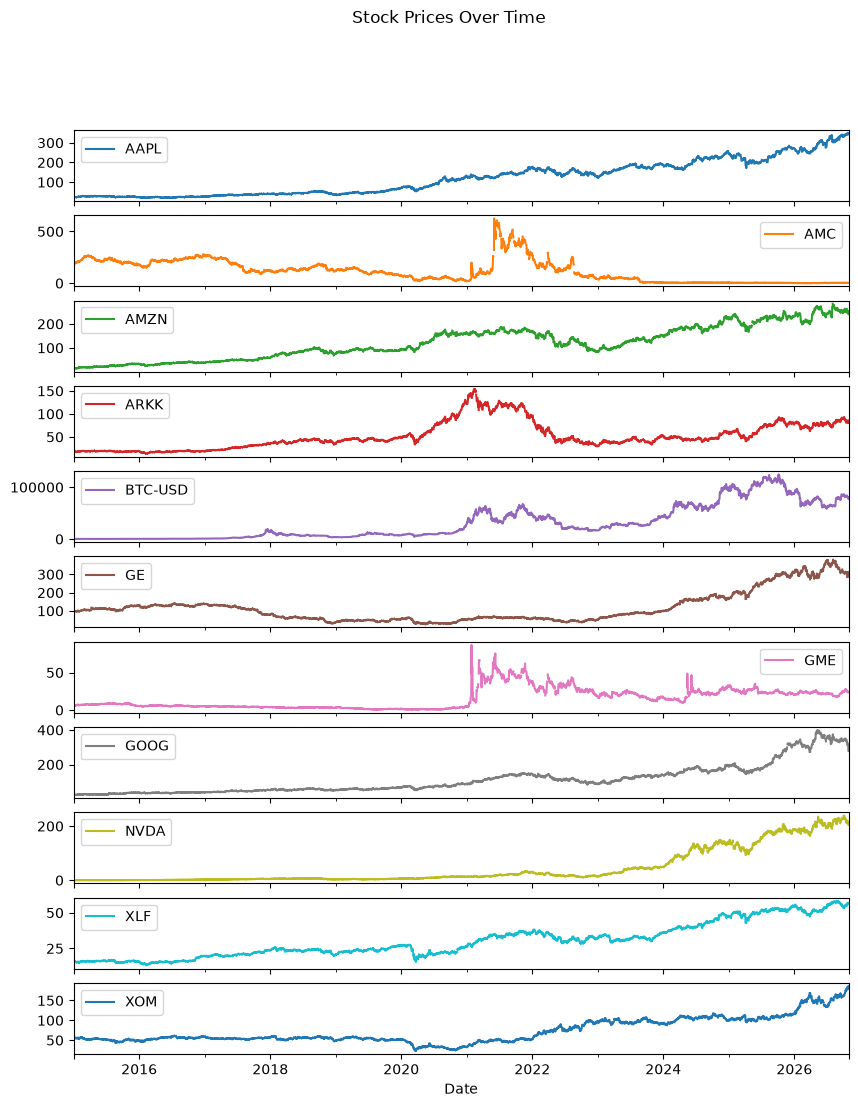

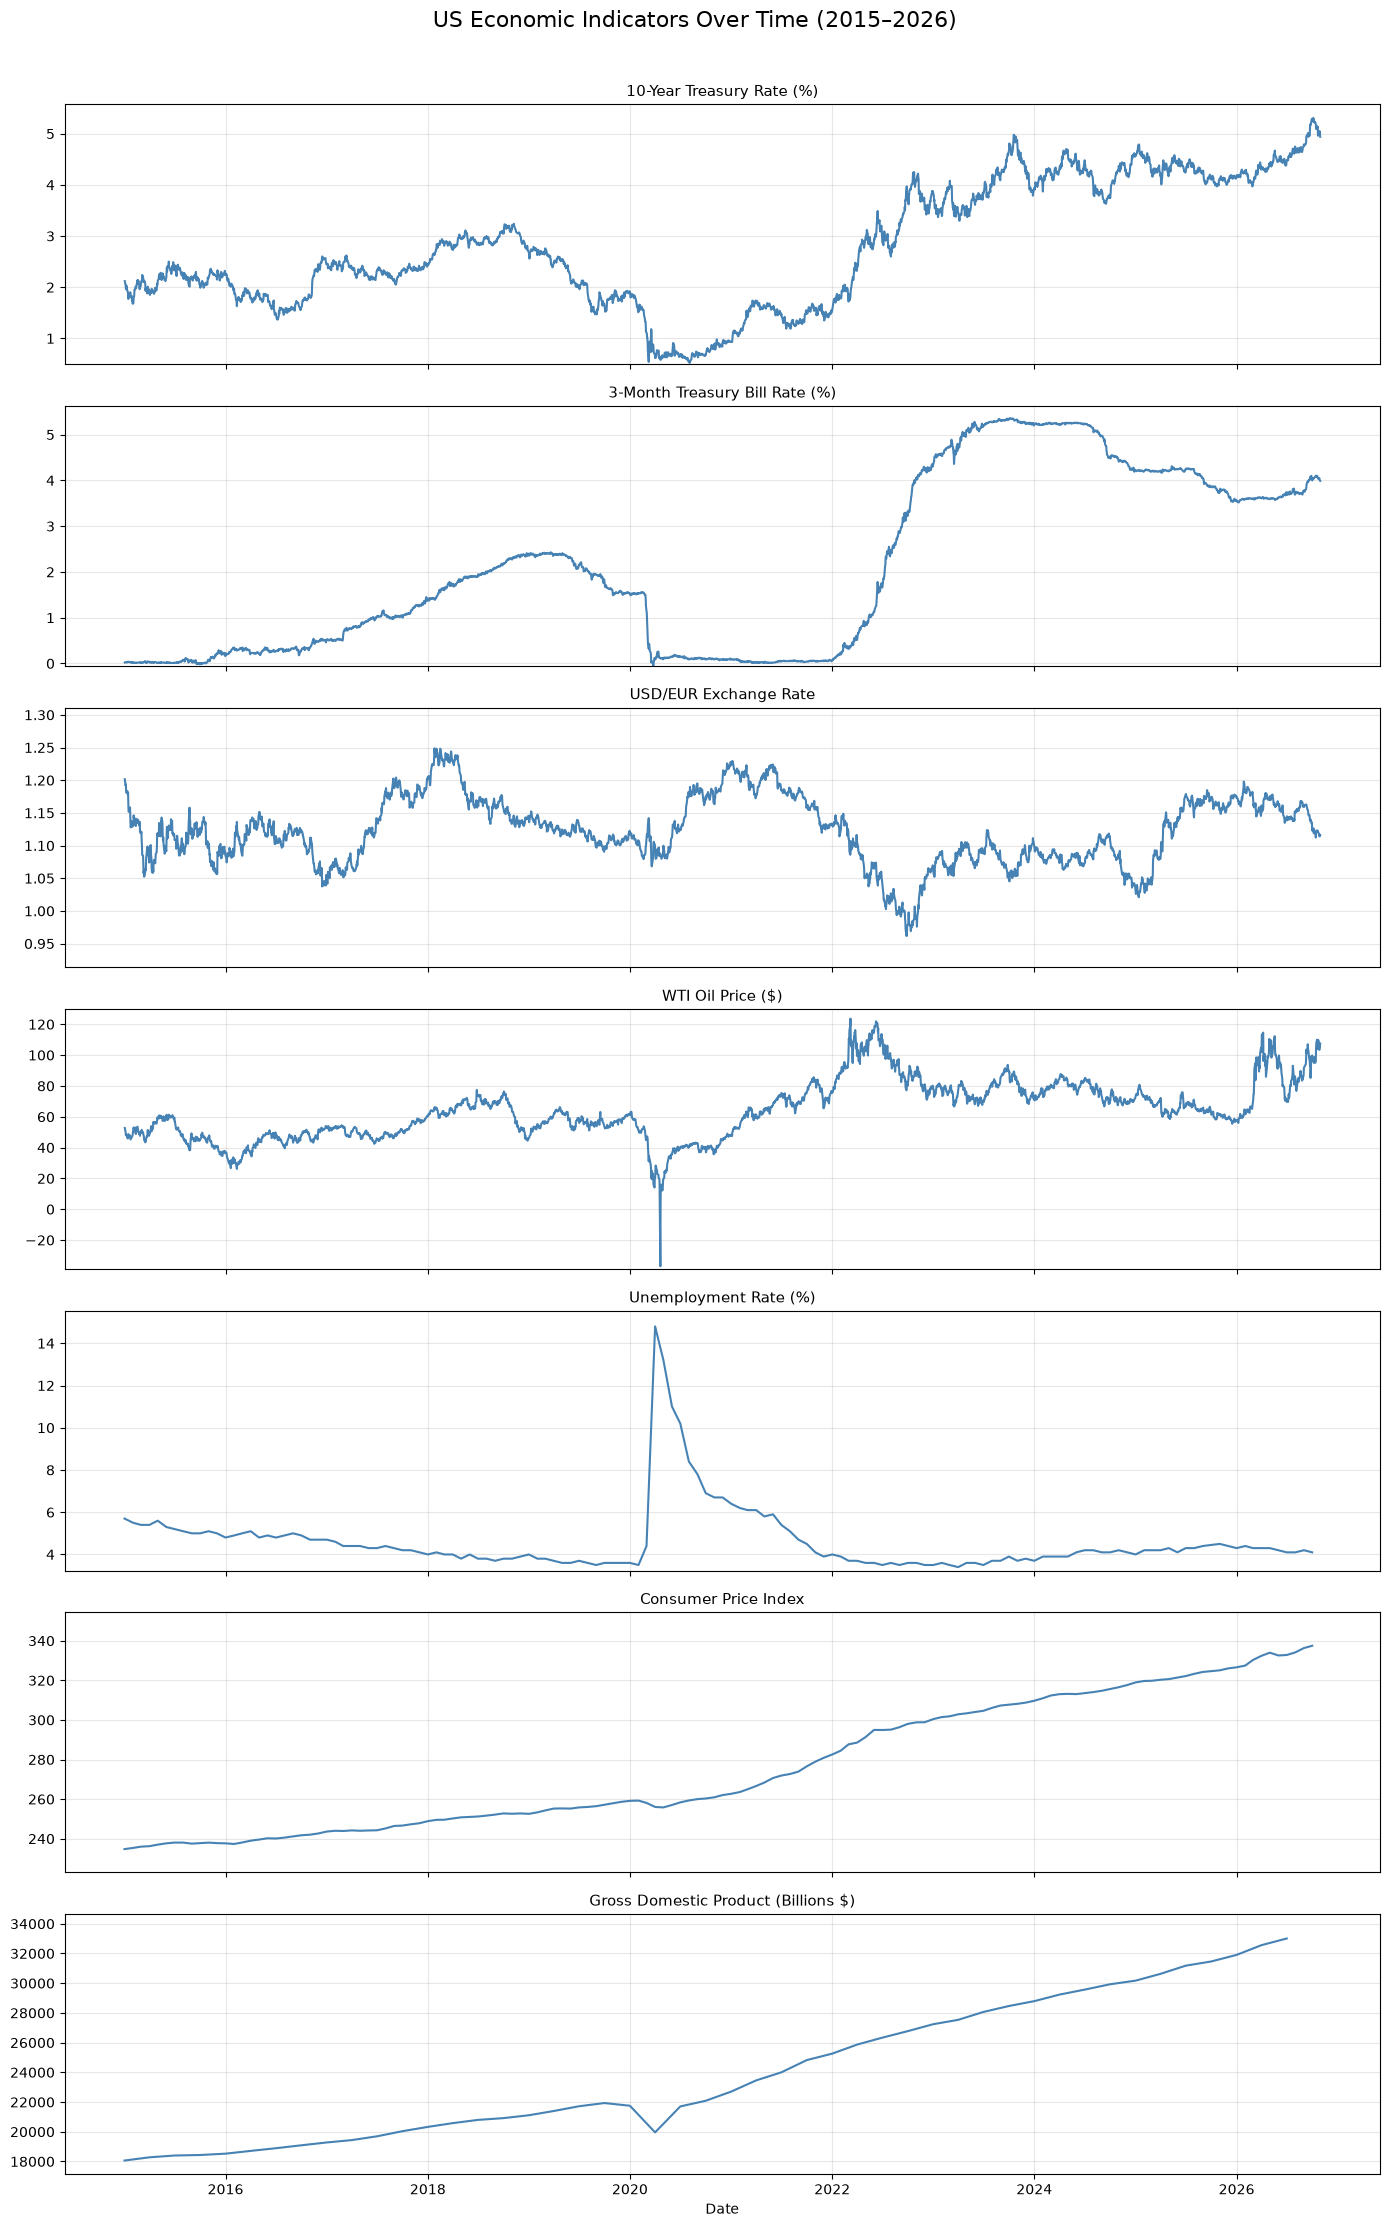

In [19]:
import matplotlib.pyplot as plt
from pandas_datareader import data as pdr

start, end = "2015-01-01", "2026-11-01"

tickers = ["NVDA", "GE", "AAPL", "GOOG", "AMZN", "XOM", "GME", "ARKK", "AMC", "BTC-USD", "XLF"]
prices = yf.download(tickers, start=start, end=end, auto_adjust=True)["Close"]

fred_codes = {
    "DGS10": "10-Year Treasury Constant Maturity Rate",
    "DTB3": "3-Month Treasury Bill: Secondary Market Rate",
    "DEXUSEU": "U.S. / Euro Foreign Exchange Rate",
    "DCOILWTICO": "Crude Oil Prices: West Texas Intermediate (WTI) - Cushing, Oklahoma",
    "UNRATE":"Unemployment",
    "CPIAUCSL":"Consumer Price Index for All Urban Consumers: All Items",
    "GDP":"Gross Domestic Product",
}

fred = pdr.DataReader(list(fred_codes.keys()), "fred", start=start, end=end)

## Plotting the stock prices
prices.plot(subplots=True, figsize=(10, 12), title="Stock Prices Over Time")
import matplotlib.pyplot as plt
import pandas as pd

# Ensure the index is datetime
fred.index = pd.to_datetime(fred.index)

# Economic indicators
indicators = {
    "DGS10": "10-Year Treasury Rate (%)",
    "DTB3": "3-Month Treasury Bill Rate (%)",
    "DEXUSEU": "USD/EUR Exchange Rate",
    "DCOILWTICO": "WTI Oil Price ($)",
    "UNRATE": "Unemployment Rate (%)",
    "CPIAUCSL": "Consumer Price Index",
    "GDP": "Gross Domestic Product (Billions $)"
}

fig, axes = plt.subplots(
    nrows=7,
    ncols=1,
    figsize=(14, 22),
    sharex=True
)

for ax, (code, title) in zip(axes, indicators.items()):

    # Extract valid observations
    series = pd.to_numeric(
        fred[code], errors="coerce"
    ).dropna()

    # Plot data
    ax.plot(
        series.index,
        series.values,
        linewidth=1.5,
        color="steelblue"
    )

    ax.set_title(title, fontsize=11)
    ax.grid(True, alpha=0.3)

    # Ensure appropriate vertical limits
    if not series.empty:
        ax.set_ylim(
            series.min() - 0.05 * abs(series.min()),
            series.max() + 0.05 * abs(series.max())
        )

axes[-1].set_xlabel("Date")

fig.suptitle(
    "US Economic Indicators Over Time (2015–2026)",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()


# Save the data to csv files
prices.to_csv("stock_prices.csv") 
fred.to_csv("economic_indicators.csv")


In [20]:
indicators = ["UNRATE", "CPIAUCSL", "GDP"]

for indicator in indicators:
    print(f"\n--- {indicator} ---")
    print(fred[indicator].dropna().head())
    print("Available observations:", fred[indicator].count())


--- UNRATE ---
DATE
2015-01-01    5.7
2015-02-01    5.5
2015-03-01    5.4
2015-04-01    5.4
2015-05-01    5.6
Name: UNRATE, dtype: float64
Available observations: 141

--- CPIAUCSL ---
DATE
2015-01-01    234.747
2015-02-01    235.342
2015-03-01    235.976
2015-04-01    236.222
2015-05-01    237.001
Name: CPIAUCSL, dtype: float64
Available observations: 141

--- GDP ---
DATE
2015-01-01    18063.529
2015-04-01    18279.784
2015-07-01    18401.626
2015-10-01    18435.137
2016-01-01    18525.933
Name: GDP, dtype: float64
Available observations: 47


In [21]:
import sys
print(sys.version)
print(sys.executable)

3.13.17 (tags/v3.13.17:64e080d, Oct 21 2026, 14:08:53) [MSC v.1944 64 bit (AMD64)]
c:\Users\pc\Documents\Projects\financial_mathematics_intro\stock_env\Scripts\python.exe


In [22]:
import pandas as pd
print(pd.__version__)

3.1.1


In [23]:
import pandas as pd
stock_prices = pd.read_csv("stock_prices.csv", index_col=0, parse_dates=True)
econ = pd.read_csv("economic_indicators.csv", index_col=0, parse_dates=True)

for name, df in  [("stocks", stock_prices), ("economic indicators", econ)]:
    print(f"\n{name.capitalize()} DataFrame Info:")
    print(df.info())
    print(f"\n{name.capitalize()} DataFrame Head:")
    print(df.head())


Stocks DataFrame Info:
<class 'pandas.DataFrame'>
DatetimeIndex: 4322 entries, 2015-01-01 to 2026-10-31
Data columns (total 11 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   AAPL     2975 non-null   float64
 1   AMC      2975 non-null   float64
 2   AMZN     2975 non-null   float64
 3   ARKK     2975 non-null   float64
 4   BTC-USD  4322 non-null   float64
 5   GE       2975 non-null   float64
 6   GME      2975 non-null   float64
 7   GOOG     2975 non-null   float64
 8   NVDA     2975 non-null   float64
 9   XLF      2975 non-null   float64
 10  XOM      2975 non-null   float64
dtypes: float64(11)
memory usage: 405.2 KB
None

Stocks DataFrame Head:
                 AAPL         AMC     AMZN       ARKK     BTC-USD          GE  \
Date                                                                            
2015-01-01        NaN         NaN      NaN        NaN  314.248993         NaN   
2015-01-02  24.153404  189.002686  15.4260  18.202000

In [24]:
# set the index to datetime for both DataFrames
prices = stock_prices.sort_index()
econ = econ.sort_index()

In [25]:
import numpy as np
# Align frequencies of the two DataFrames
prices_m = prices.resample('ME').last()
ret_m = np.log(prices_m / prices_m.shift(1))
econ_m = econ.resample('ME').last().ffill()
df = ret_m.join(econ_m, how='inner').dropna()

In [26]:
pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [27]:
# stationary and macro changes
from statsmodels.tsa.stattools import adfuller

econ_diff = econ_m.pct_change().replace([np.inf, -np.inf], np.nan)
df = ret_m.join(econ_diff.shift(1), how='inner').dropna()  

for c in df.columns:
    result = adfuller(df[c].dropna())
    print(f"\nADF Test for {c}:")
    print(f"ADF Statistic: {result[0]}")
    print(f"p-value: {result[1]}")
    print(f"Critical Values: {result[4]}")


ADF Test for AAPL:
ADF Statistic: -9.073124703052578
p-value: 4.249070936231055e-15
Critical Values: {'1%': np.float64(-3.47864788917503), '5%': np.float64(-2.882721765644168), '10%': np.float64(-2.578065326612056)}

ADF Test for AMC:
ADF Statistic: -14.698077510347526
p-value: 2.976475555247099e-27
Critical Values: {'1%': np.float64(-3.4782936965183815), '5%': np.float64(-2.882567574015525), '10%': np.float64(-2.5779830117488745)}

ADF Test for AMZN:
ADF Statistic: -12.819936351014281
p-value: 6.184169156179215e-24
Critical Values: {'1%': np.float64(-3.4782936965183815), '5%': np.float64(-2.882567574015525), '10%': np.float64(-2.5779830117488745)}

ADF Test for ARKK:
ADF Statistic: -11.560303433495672
p-value: 3.2825136945275618e-21
Critical Values: {'1%': np.float64(-3.4782936965183815), '5%': np.float64(-2.882567574015525), '10%': np.float64(-2.5779830117488745)}

ADF Test for BTC-USD:
ADF Statistic: -10.173027751484941
p-value: 7.008383933487102e-18
Critical Values: {'1%': np.floa

C:\Users\pc\AppData\Local\Temp\ipykernel_18340\171627317.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df[c].dropna())
C:\Users\pc\AppData\Local\Temp\ipykernel_18340\171627317.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df[c].dropna())
C:\Users\pc\AppData\Local\Temp\ipykernel_18340\171627317.py:8: FutureWarning: adfuller c

### Visualize the relationships between stocks and macro variables

In [28]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


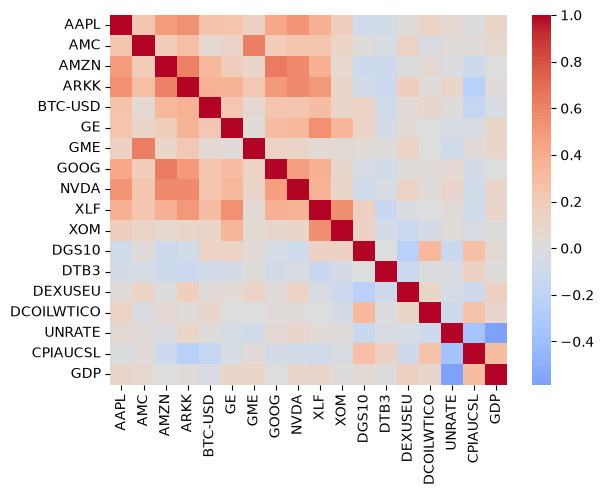

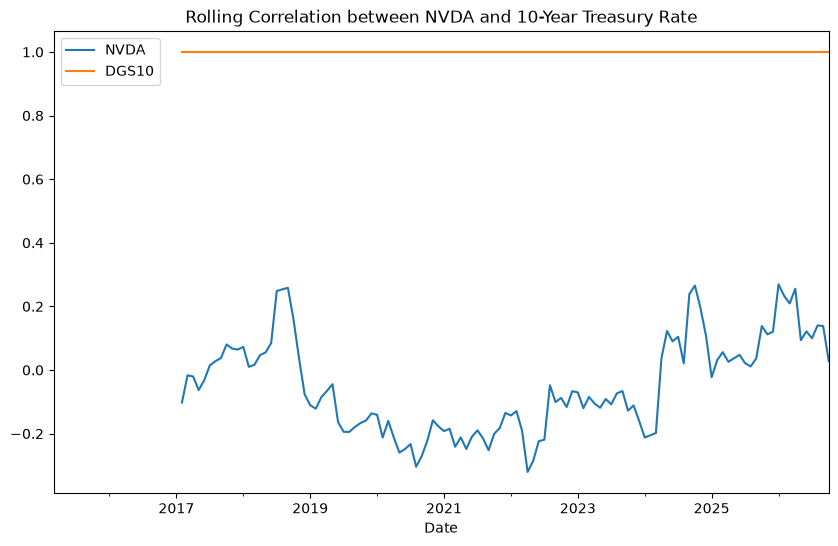

In [29]:
import seaborn as sns, matplotlib.pyplot as plt
sns.heatmap(df.corr(), cmap='coolwarm', annot=False, fmt=".2f", center=0)
plt.show()
# rolling correlation
df[['NVDA', 'DGS10']].rolling(window=24).corr(df[econ_diff.columns[0]]).plot(figsize=(10, 6), title='Rolling Correlation between NVDA and 10-Year Treasury Rate')
plt.show()

## Regression and Causality

In [30]:
import statsmodels.api as sm
from statsmodels.tsa.stattools import grangercausalitytests

y =df['NVDA']
X = sm.add_constant(df[econ_diff.columns])  
print(sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3}).summary())

grangercausalitytests(df[['NVDA', econ_diff.columns[0]]] , maxlag=12)

                            OLS Regression Results                            
Dep. Variable:                   NVDA   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                  0.015
Method:                 Least Squares   F-statistic:                     8.053
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           3.90e-08
Time:                        20:51:06   Log-Likelihood:                 95.544
No. Observations:                 140   AIC:                            -175.1
Df Residuals:                     132   BIC:                            -151.6
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0395      0.016      2.498      0.0

{np.int64(1): ({'ssr_ftest': (np.float64(1.1933204599887905),
    np.float64(0.27659212382523796),
    np.float64(136.0),
    np.int64(1)),
   'ssr_chi2test': (np.float64(1.2196437054297198),
    np.float64(0.2694305862980637),
    np.int64(1)),
   'lrtest': (np.float64(1.2143239710521812),
    np.float64(0.2704774581512878),
    np.int64(1)),
   'params_ftest': (np.float64(1.1933204599887832),
    np.float64(0.27659212382523934),
    np.float64(136.0),
    1.0)},
   array([[0., 1., 0.]])]),
 np.int64(2): ({'ssr_ftest': (np.float64(2.359218327187339),
    np.float64(0.09843749071709862),
    np.float64(133.0),
    np.int64(2)),
   'ssr_chi2test': (np.float64(4.8958214910053055),
    np.float64(0.08647406422936252),
    np.int64(2)),
   'lrtest': (np.float64(4.810977881331041),
    np.float64(0.09022137192609804),
    np.int64(2)),
   'params_ftest': (np.float64(2.35921832718734),
    np.float64(0.0984374907170985),
    np.float64(133.0),
    2.0)},
   array([[0., 0., 1., 0., 0.],
     

Selected lags: 0


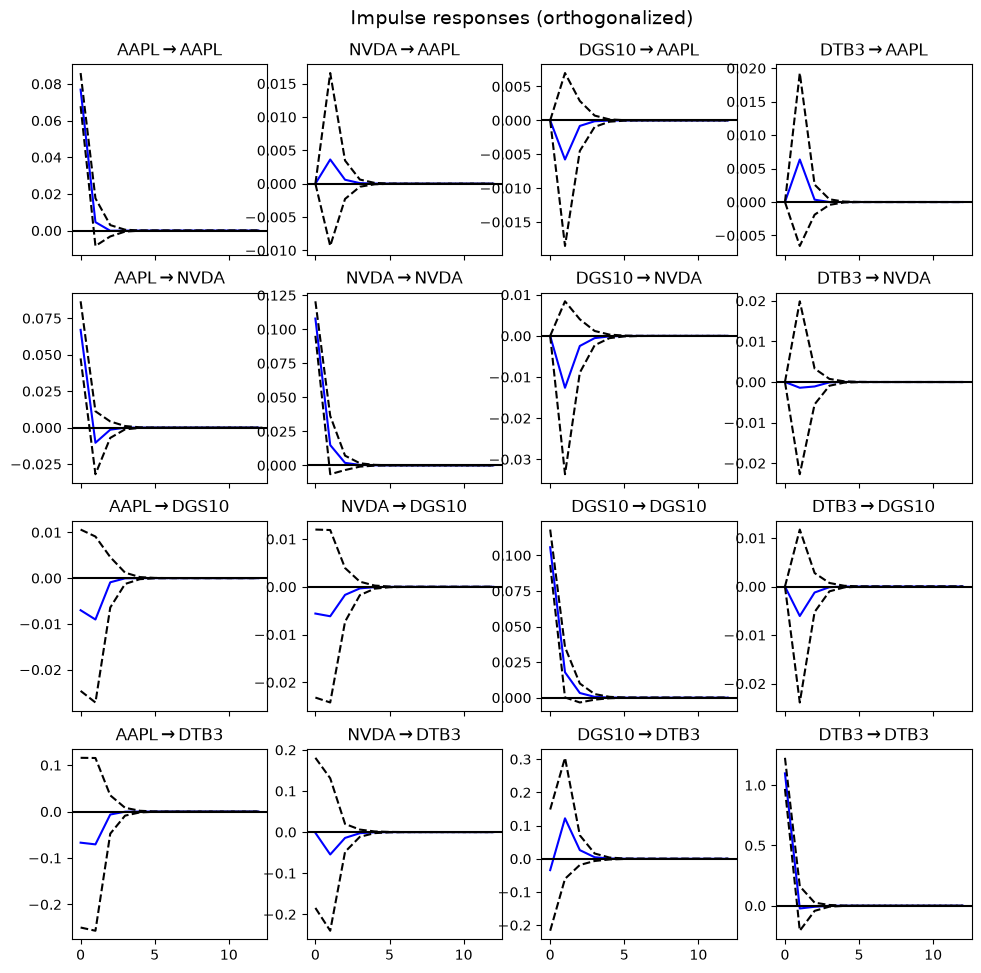

In [31]:
from statsmodels.tsa.api import VAR
import matplotlib.pyplot as plt

# Define the variables
data = df[["AAPL", "NVDA"] + list(econ_diff.columns[:2])]

# Fit VAR with 1 to 6 lags
model = VAR(data)
res = model.fit(maxlags=6, ic='aic')

# Check selected lags
print("Selected lags:", res.k_ar)

# If AIC selected zero lags, force one lag
if res.k_ar == 0:
    res = model.fit(1)

# Plot impulse response functions
irf = res.irf(12)
irf.plot(orth=True)
plt.show()

## Interepretation of the results:
A. AAPL → AAPL (Apple's reaction to its own shock)

What we observe:
- Apple has a strong positive response immediately following its own shock.
- The response decreases very quickly.
- After approximately 3–4 periods, the response becomes almost zero.
Interpretation:

An unexpected positive shock to Apple's returns has an immediate positive effect on its returns, but this effect does not persist for very long.

This suggests that Apple's return shocks are relatively short-lived in our estimated model.

B. NVDA → AAPL (Nvidia's effect on Apple)

What we observe:
- A positive response in Apple following a Nvidia shock.
- The response reaches a small positive peak after approximately one period.
- The effect quickly disappears.
Interpretation:

Our model suggests that positive shocks to Nvidia are followed by a small positive response in Apple.

This could be consistent with the idea that the two companies are exposed to common market or technology-sector factors.

However, looking at the confidence intervals: they include zero. Therefore, we do not have strong statistical evidence that this relationship is different from zero.

C. DGS10 → AAPL (10-year Treasury yield → Apple)

What we observe:
- A negative response in Apple following a positive shock to DGS10.
- The negative effect is strongest around the first period.
- The response disappears after a few periods.
Interpretation:

Our model suggests that a positive shock to the 10-year Treasury yield is followed by a negative reaction in Apple's returns.

This is economically plausible:

Higher long-term interest rates can:
- Increase the discount rate used to value future corporate earnings.
- Reduce the present value of future cash flows.
- Make bonds relatively more attractive compared with equities.
Technology companies, whose valuations can depend heavily on expected future growth, may be particularly sensitive to interest rates.

However, the confidence intervals in the graph are broad and include zero, so this relationship is not statistically established by these results.

D. DTB3 → AAPL (3-month Treasury rate → Apple)
What we observe:
- A positive response immediately after the shock.
- The response disappears quickly.
This is interesting because it differs from the negative response observed for DGS10.

However, we should be careful about interpreting this difference economically.

The 3-month and 10-year rates capture different parts of the yield curve, and their estimated responses can differ.

Again, the confidence intervals suggest considerable uncertainty.

E. What happens to Nvidia?
It is represented in the next row:

Some interesting observations:
- AAPL → NVDA: Apple's shock produces a small negative response in Nvidia.
- NVDA → NVDA: Nvidia responds strongly and positively to its own shock.
- DGS10 → NVDA: A positive shock to the 10-year yield is followed by a negative response in Nvidia.
- DTB3 → NVDA: The estimated response is small and slightly negative.
The most noticeable result is Nvidia's strong own response.

Like Apple, Nvidia's response to its own shock declines rapidly.
F. What happens to interest rates?
Looking at the third row, which represents responses in DGS10.

The most interesting graph is:

DGS10 → DGS10

It shows a strong positive response to its own shock, followed by a rapid decline.

This means an unexpected increase in the 10-year yield has an immediate effect on the yield itself, but the effect gradually disappears in the estimated model.

The other graphs suggest relatively small responses of DGS10 to shocks in Apple, Nvidia and DTB3.

G. What happens to DTB3?
The fourth row shows responses in the 3-month Treasury bill rate.

The most noticeable relationships are:
- AAPL → DTB3: Negative response.
- NVDA → DTB3: Negative response.
- DGS10 → DTB3: Positive response.
- DTB3 → DTB3: Strong positive own response.
The positive response of DTB3 to DGS10 shocks is particularly interesting.

It suggests that an unexpected increase in the 10-year yield is followed by an increase in the 3-month rate in our estimated model.

However, the confidence intervals are again important when deciding whether these relationships are statistically meaningful.

### Validate the VAR model

In [32]:
model = VAR(df[["AAPL", "NVDA"] + list(econ_diff.columns[:2])])
res = model.fit(maxlags=6, ic="aic")

In [33]:
from statsmodels.tsa.stattools import adfuller

variables = ["AAPL", "NVDA"] + list(econ_diff.columns[:2])

for col in variables:
    result = adfuller(df[col].dropna())

    print(f"\n{col}")
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])

    if result[1] < 0.05:
        print("Stationary")
    else:
        print("Potentially non-stationary")


AAPL
ADF Statistic: -9.073124703052578
p-value: 4.249070936231055e-15
Stationary

NVDA
ADF Statistic: -11.006230196583559
p-value: 6.49369925143605e-20
Stationary

DGS10
ADF Statistic: -6.485515613465731
p-value: 1.2638083908850094e-08
Stationary

DTB3
ADF Statistic: -11.894907344498908
p-value: 5.752585906911522e-22
Stationary


C:\Users\pc\AppData\Local\Temp\ipykernel_18340\1495535906.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df[col].dropna())
C:\Users\pc\AppData\Local\Temp\ipykernel_18340\1495535906.py:6: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(df[col].dropna())
C:\Users\pc\AppData\Local\Temp\ipykernel_18340\1495535906.py:6: FutureWarning: adf

The ADF test evaluates two hypotheses:
- H₀ (null hypothesis): The series has a unit root, meaning it is non-stationary.
- H₁ (alternative hypothesis): The series is stationary.
Your results:
Variable	ADF statistic	p-value	Conclusion
AAPL	-9.07	4.25 × 10⁻¹⁵	Stationary
NVDA	-11.01	6.49 × 10⁻²⁰	Stationary
DGS10	-6.49	1.26 × 10⁻⁸	Stationary
DTB3	-11.89	5.75 × 10⁻²²	Stationary

All p-values are far below 0.01.

Therefore, you reject the null hypothesis for all four variables.

## Trying other VARs: VAR(1), VAR(2)

In [48]:
from statsmodels.tsa.api import VAR

variables = ["AAPL", "NVDA", "DGS10", "DTB3"]

model = VAR(df[variables])

results = {}

for p in [1, 2, 3]:

    fitted = model.fit(p)

    results[p] = fitted

    print(f"\n--- VAR({p}) ---")

    print("AIC:", fitted.aic)
    print("BIC:", fitted.bic)
    print("HQIC:", fitted.hqic)

    print("Stable:", fitted.is_stable())

    print("Residual autocorrelation:")

    print(fitted.test_whiteness(
        nlags=12,
        adjusted=True
    ).summary())


--- VAR(1) ---
AIC: -13.749826780738644
BIC: -13.327600315539984
HQIC: -13.578245178424869
Stable: True
Residual autocorrelation:
Adjusted Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value  df
-----------------------------------------
         184.3          208.0   0.318 176
-----------------------------------------

--- VAR(2) ---
AIC: -13.600578879020453
BIC: -12.836947482892487
HQIC: -13.290257955018486
Stable: True
Residual autocorrelation:
Adjusted Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value  df
-----------------------------------------
         170.8          190.5   0.264 160
-----------------------------------------

--- VAR(3) ---
AIC: -13.7426607712843
BIC: -12.634346843232748
HQIC: -1

In [36]:
serial_test = res.test_whiteness(
    nlags=12,
    adjusted=True
)

print(serial_test.summary())

Adjusted Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 12 is zero. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value  df
-----------------------------------------
         208.0          225.3   0.204 192
-----------------------------------------


### Normality of residuals

In [37]:
normality_test = res.test_normality()

print(normality_test.summary())

normality (skew and kurtosis) test. H_0: data generated by normally-distributed process. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value df
----------------------------------------
     1.202e+04          15.51   0.000  8
----------------------------------------


The VAR residuals do not follow a multivariate normal distribution

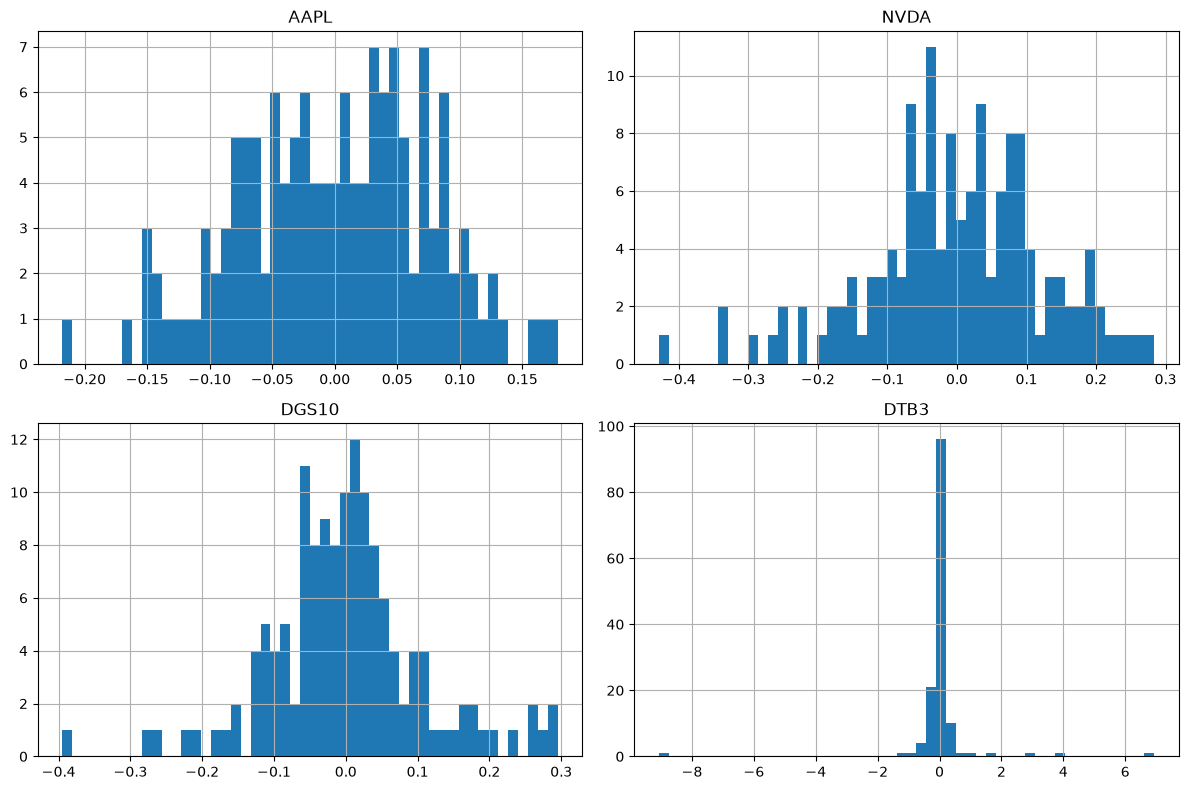

In [40]:
import matplotlib.pyplot as plt

residuals = res.resid

residuals.hist(bins=50, figsize=(12, 8))
plt.tight_layout()
plt.show()

Looking at our plots:
- AAPL: Appears reasonably concentrated around zero, with some asymmetry and possible tail observations.
- NVDA: Also concentrated around zero, with some relatively extreme observations.
- DGS10: Appears somewhat asymmetric, with observations in the tails.
- DTB3: Has a particularly unusual distribution, with a very large concentration around zero and some extreme observations.
This is consistent with our multivariate normality test rejecting normality.

One thing deserves special attention: the DTB3 residuals appear to have extreme values relative to their central concentration.

Before interpreting this as genuine financial behaviour, we will check the underlying observations. Possible explanations include:
- Genuine extreme market movements.
- Data errors or incorrect observations.
- Different units or scales.
- Missing-value codes accidentally treated as numerical observations.
- A structural break in the data.

We can investigate with:

In [41]:
print(res.resid.describe())
print(res.resid.quantile([0, 0.01, 0.05, 0.5, 0.95, 0.99, 1]))

               AAPL          NVDA         DGS10          DTB3
count  1.400000e+02  1.400000e+02  1.400000e+02  1.400000e+02
mean   1.809069e-18 -8.723181e-18  1.586033e-18 -1.268826e-17
std    7.631755e-02  1.268843e-01  1.075085e-01  1.091544e+00
min   -2.177133e-01 -4.286078e-01 -3.945431e-01 -9.067389e+00
25%   -5.628534e-02 -6.864808e-02 -5.586818e-02 -8.547067e-02
50%    5.346788e-03  4.946216e-03  9.298790e-06 -6.355352e-02
75%    5.426471e-02  7.798819e-02  4.532679e-02 -2.272361e-03
max    1.782339e-01  2.834799e-01  2.950788e-01  6.932611e+00
          AAPL      NVDA     DGS10      DTB3
0.00 -0.217713 -0.428608 -0.394543 -9.067389
0.01 -0.161473 -0.330713 -0.269188 -1.109319
0.05 -0.134843 -0.228491 -0.159488 -0.402237
0.50  0.005347  0.004946  0.000009 -0.063554
0.95  0.109478  0.197003  0.194698  0.478571
0.99  0.161024  0.259792  0.279676  3.542611
1.00  0.178234  0.283480  0.295079  6.932611


In [42]:
print(res.resid["DTB3"].abs().nlargest(10))

Date
2015-11-30    9.067389
2015-08-31    6.932611
2021-07-31    3.932611
2022-02-28    2.932611
2015-12-31    1.682611
2015-10-31    1.192389
2020-04-30    0.979389
2016-02-29    0.932611
2015-05-31    0.734055
2021-05-31    0.734055
Name: DTB3, dtype: float64


In [45]:
# Inspect the original DTB3 variable
print(df["DTB3"].describe())

# Inspect the observations with the largest residuals
extreme_dates = res.resid["DTB3"].abs().nlargest(10).index

print(df.loc[extreme_dates, "DTB3"])
print(res.resid.loc[extreme_dates, "DTB3"])

count    140.000000
mean       0.067389
std        1.091544
min       -9.000000
25%       -0.018082
50%        0.003835
75%        0.065116
max        7.000000
Name: DTB3, dtype: float64
Date
2015-11-30   -9.000000
2015-08-31    7.000000
2021-07-31    4.000000
2022-02-28    3.000000
2015-12-31    1.750000
2015-10-31   -1.125000
2020-04-30   -0.912000
2016-02-29    1.000000
2015-05-31   -0.666667
2021-05-31   -0.666667
Name: DTB3, dtype: float64
Date
2015-11-30   -9.067389
2015-08-31    6.932611
2021-07-31    3.932611
2022-02-28    2.932611
2015-12-31    1.682611
2015-10-31   -1.192389
2020-04-30   -0.979389
2016-02-29    0.932611
2015-05-31   -0.734055
2021-05-31   -0.734055
Name: DTB3, dtype: float64


In [46]:
from statsmodels.tsa.api import VAR

model = VAR(df[["AAPL", "NVDA", "DGS10", "DTB3"]])

lag_selection = model.select_order(maxlags=15)

print(lag_selection.summary())

 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0      -15.44*     -15.35*  1.975e-07*     -15.40*
1       -15.31      -14.86   2.243e-07      -15.13
2       -15.32      -14.51   2.219e-07      -14.99
3       -15.24      -14.06   2.412e-07      -14.76
4       -15.20      -13.66   2.531e-07      -14.57
5       -15.09      -13.19   2.841e-07      -14.31
6       -14.98      -12.72   3.197e-07      -14.06
7       -14.88      -12.25   3.584e-07      -13.81
8       -14.74      -11.76   4.162e-07      -13.53
9       -14.62      -11.27   4.815e-07      -13.26
10      -14.72      -11.01   4.456e-07      -13.22
11      -14.72      -10.65   4.633e-07      -13.07
12      -14.58      -10.14   5.568e-07      -12.78
13      -14.60      -9.800   5.755e-07      -12.65
14      -14.48      -9.319   6.893e-07      -12.38
15      -14.58      -9.059   6.699e-07      -12.34
-------------------------------

#### Interpretation:

### VAR Stability

In [44]:
print("Selected lag order:", res.k_ar)
print("Coefficient matrices:", len(res.coefs))
print("Model parameters:", res.params)

Selected lag order: 0
Coefficient matrices: 0
Model parameters:            AAPL      NVDA     DGS10      DTB3
const  0.017801  0.042542  0.014012  0.067389


In [53]:
from statsmodels.tsa.api import VAR

variables = ["AAPL", "NVDA", "DGS10", "DTB3"]

# Ensure all models use exactly the same observations
data = df[variables].dropna()

model = VAR(data)

# Estimate candidate models
var1 = model.fit(1)
var2 = model.fit(2)
var3 = model.fit(3)

In [54]:
print("VAR is stable:", var3.is_stable())

VAR is stable: True


In [55]:
# Does NVDA Granger-cause AAPL?
print(
    var3.test_causality(
        caused="AAPL",
        causing=["NVDA"],
        kind="f"
    ).summary()
)

Granger causality F-test. H_0: NVDA does not Granger-cause AAPL. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value    df   
----------------------------------------------
         1.114          2.623   0.343 (3, 496)
----------------------------------------------


### Some investigatons

In [56]:
print("Lag 1 coefficients:")
print(var3.coefs[0])

print("\nLag 2 coefficients:")
print(var3.coefs[1])

print("\nLag 3 coefficients:")
print(var3.coefs[2])

Lag 1 coefficients:
[[ 0.03850811 -0.00147374 -0.03832801  0.00729819]
 [-0.26482932  0.07740328 -0.08525826  0.00161605]
 [-0.06351601 -0.02776049  0.157988   -0.00729221]
 [ 0.01481802 -0.19394155  1.09004464 -0.04531271]]

Lag 2 coefficients:
[[-0.21085378  0.07931651 -0.09225318  0.00214484]
 [-0.29640406  0.10706229 -0.19296883  0.00261078]
 [ 0.06495895  0.04565827  0.17486913  0.00483288]
 [ 1.57274565 -1.23462392 -0.66449408 -0.06562296]]

Lag 3 coefficients:
[[-7.06499991e-02  7.50405105e-02 -1.52691457e-02  1.15051147e-03]
 [-1.21929408e-01  8.90467889e-02 -8.38523577e-02  6.67061062e-03]
 [ 3.22973571e-01 -1.32857257e-01 -9.21701071e-02  2.19572037e-02]
 [ 1.50771631e+00 -8.81608418e-01  9.51082833e-01 -4.58490895e-01]]


In [58]:
for caused in variables:

    for causing in variables:

        if caused != causing:

            test = var3.test_causality(
                caused=caused,
                causing=[causing],
                kind="f"
            )

            print(f"\n{causing} -> {caused}")
            print("p-value:", test.pvalue)


NVDA -> AAPL
p-value: 0.3428795612411753

DGS10 -> AAPL
p-value: 0.3900446018575708

DTB3 -> AAPL
p-value: 0.6736918306911192

AAPL -> NVDA
p-value: 0.089437588443754

DGS10 -> NVDA
p-value: 0.11705166202136194

DTB3 -> NVDA
p-value: 0.9149014635374044

AAPL -> DGS10
p-value: 0.10355162429100385

NVDA -> DGS10
p-value: 0.4179809434078595

DTB3 -> DGS10
p-value: 0.03458285885222405

AAPL -> DTB3
p-value: 0.40458293028048453

NVDA -> DTB3
p-value: 0.25367149316457266

DGS10 -> DTB3
p-value: 0.3020941277485712


the historical behaviour of AAPL might contain information useful for predicting NVDA, while historical NVDA might contain less information for predicting AAPL.

## A. Forecast Error Variance Decomposition (FEVD)

In [60]:
fevd = var3.fevd(12)

print(fevd.summary())

FEVD for AAPL
          AAPL      NVDA     DGS10      DTB3
0     1.000000  0.000000  0.000000  0.000000
1     0.989679  0.000013  0.001774  0.008534
2     0.962593  0.013375  0.015027  0.009006
3     0.949095  0.024466  0.017557  0.008882
4     0.944602  0.024456  0.017999  0.012943
5     0.943222  0.024413  0.018339  0.014026
6     0.942998  0.024638  0.018343  0.014022
7     0.942327  0.024738  0.018328  0.014607
8     0.942240  0.024744  0.018327  0.014689
9     0.942212  0.024763  0.018329  0.014695
10    0.942057  0.024786  0.018326  0.014831
11    0.942044  0.024789  0.018326  0.014841

FEVD for NVDA
          AAPL      NVDA     DGS10      DTB3
0     0.252374  0.747626  0.000000  0.000000
1     0.260492  0.734908  0.004448  0.000152
2     0.263364  0.708165  0.028226  0.000246
3     0.260058  0.702888  0.035434  0.001620
4     0.259667  0.701515  0.036345  0.002473
5     0.259637  0.699726  0.036679  0.003958
6     0.259464  0.698899  0.036632  0.005006
7     0.259471  0.698847  

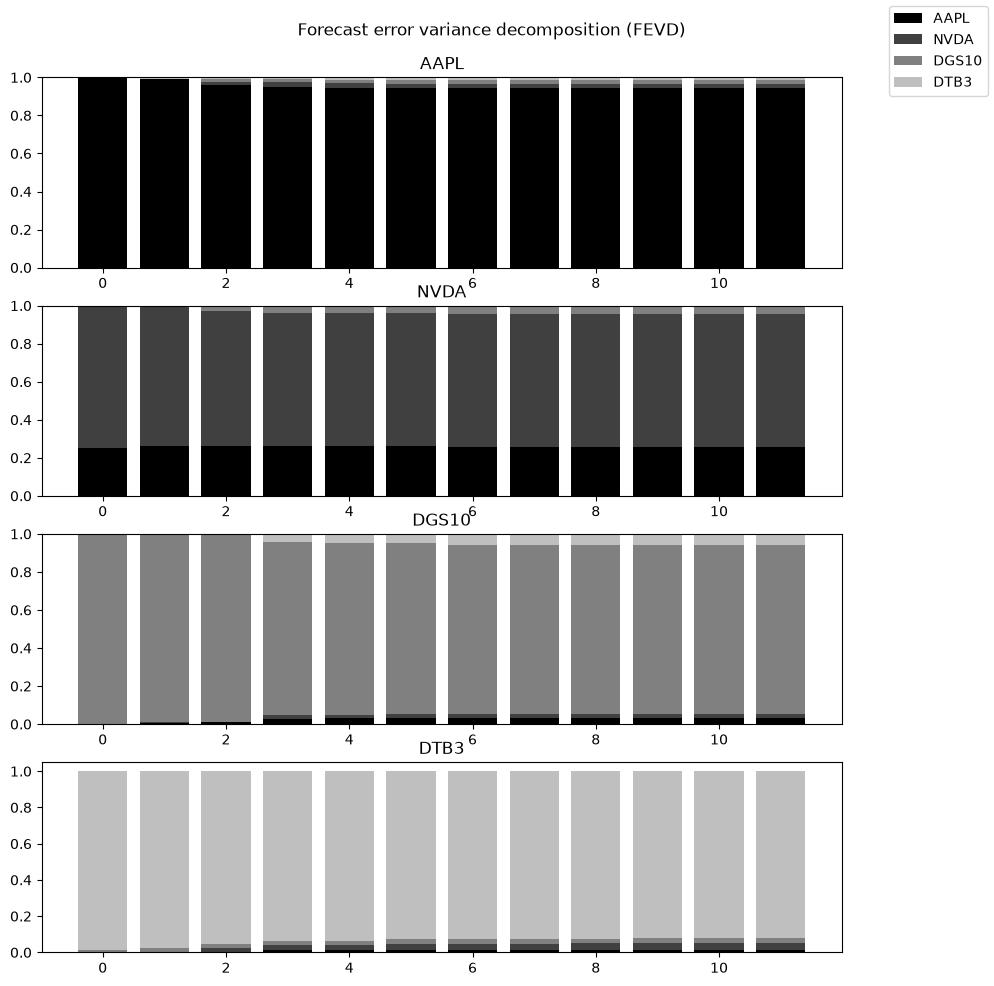

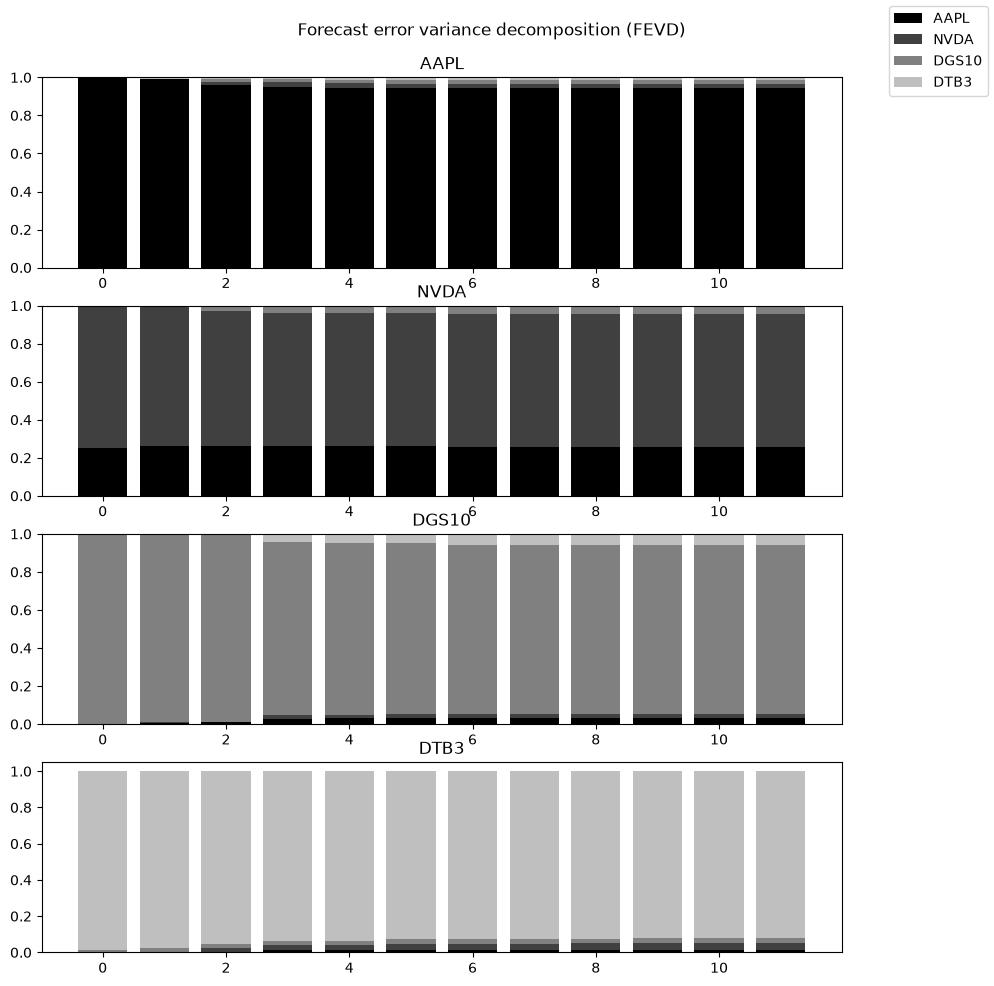

In [61]:
fevd.plot()

## B. Forcasting

In [62]:
import pandas as pd

lag_order = var3.k_ar

forecast = var3.forecast(
    data.values[-lag_order:],
    steps=3
)

forecast_df = pd.DataFrame(
    forecast,
    columns=variables
)

print(forecast_df)

       AAPL      NVDA     DGS10      DTB3
0  0.010863  0.008539  0.020254  0.342663
1 -0.008288 -0.002538  0.037002  0.285797
2  0.002012  0.018260  0.035123  0.362758


In [63]:
for i, coef in enumerate(var3.coefs):

    print(f"\nLAG {i+1}")

    coef_df = pd.DataFrame(
        coef,
        index=variables,
        columns=variables
    )

    print(coef_df)


LAG 1
           AAPL      NVDA     DGS10      DTB3
AAPL   0.038508 -0.001474 -0.038328  0.007298
NVDA  -0.264829  0.077403 -0.085258  0.001616
DGS10 -0.063516 -0.027760  0.157988 -0.007292
DTB3   0.014818 -0.193942  1.090045 -0.045313

LAG 2
           AAPL      NVDA     DGS10      DTB3
AAPL  -0.210854  0.079317 -0.092253  0.002145
NVDA  -0.296404  0.107062 -0.192969  0.002611
DGS10  0.064959  0.045658  0.174869  0.004833
DTB3   1.572746 -1.234624 -0.664494 -0.065623

LAG 3
           AAPL      NVDA     DGS10      DTB3
AAPL  -0.070650  0.075041 -0.015269  0.001151
NVDA  -0.121929  0.089047 -0.083852  0.006671
DGS10  0.322974 -0.132857 -0.092170  0.021957
DTB3   1.507716 -0.881608  0.951083 -0.458491


There are three particularly interesting things in our outputs:
1. AAPL is largely driven by its own shocks.
2. NVDA has a much stronger contribution from AAPL shocks than AAPL has from NVDA shocks.
3. DTB3 and DGS10 have a relationship that is consistent with our Granger causality results.